In [2]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

DATASET_DIR = Path(r"C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data")
CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
IMG_SIZE = (224, 224)

print("Dataset trouvé :", DATASET_DIR.exists())


Dataset trouvé : True


In [3]:
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLITS = ["Train", "Val", "Test"]

def trouver_images(split):
    images = []
    for classe in CLASSES:
        dossier = DATASET_DIR / split / classe / "images"
        if dossier.exists():
            images.extend(
                (chemin, classe)
                for chemin in dossier.iterdir()
                if chemin.is_file() and chemin.suffix.lower() in EXTENSIONS
            )
    return images

for split in SPLITS:
    print(f"{split} :", len(trouver_images(split)), "images")


Train : 4737 images
Val : 512 images
Test : 0 images


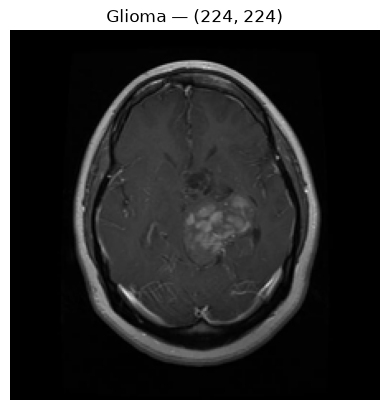

In [4]:
images_train = trouver_images("Train")

if not images_train:
    print("Aucune image trouvée. Vérifie la structure des dossiers.")
else:
    chemin_image, classe = images_train[0]

    with Image.open(chemin_image) as img:
        image = img.convert("RGB").resize(IMG_SIZE)

    plt.imshow(image)
    plt.title(f"{classe} — {image.size}")
    plt.axis("off")
    plt.show()


Dimensions : (224, 224, 3)
Valeur minimale : 0.0
Valeur maximale : 0.9137255


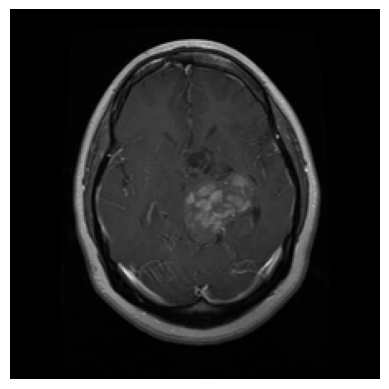

In [5]:
image_array = np.array(image, dtype=np.float32)
image_normalisee = image_array / 255.0

print("Dimensions :", image_normalisee.shape)
print("Valeur minimale :", image_normalisee.min())
print("Valeur maximale :", image_normalisee.max())

plt.imshow(image_normalisee)
plt.axis("off")
plt.show()


In [7]:
def trouver_label(chemin_image, split, classe):
    return DATASET_DIR / split / classe / "labels" / f"{chemin_image.stem}.txt"

if images_train:
    label_path = trouver_label(chemin_image, "Train", classe)
    print("Image :", chemin_image.name)
    print("Fichier label :", label_path.name)
    print("Label présent :", label_path.exists())
    if label_path.exists():
        print(label_path.read_text(encoding="utf-8"))


Image : gg (1).jpg
Fichier label : gg (1).txt
Label présent : True
0 0.567383 0.519531 0.189453 0.148438



In [8]:
def pretraiter_image(chemin, taille=IMG_SIZE):
    with Image.open(chemin) as img:
        img = img.convert("RGB").resize(taille)
        tableau = np.asarray(img, dtype=np.float32) / 255.0
    return tableau

if images_train:
    exemple = pretraiter_image(images_train[0][0])
    print("Forme de l'image prétraitée :", exemple.shape)


Forme de l'image prétraitée : (224, 224, 3)


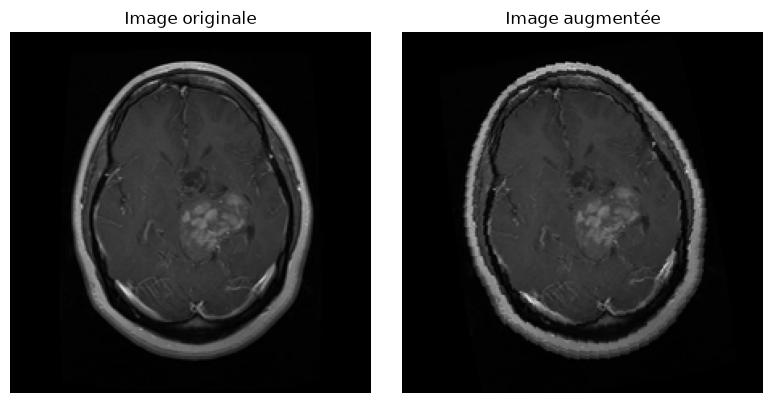

In [9]:
import random

def augmenter_pour_visualisation(image_pil):
    image_aug = image_pil.copy()
    if random.choice([True, False]):
        image_aug = image_aug.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
    angle = random.uniform(-10, 10)
    image_aug = image_aug.rotate(angle)
    return image_aug

if images_train:
    with Image.open(images_train[0][0]) as img:
        original = img.convert("RGB").resize(IMG_SIZE)

    augmentee = augmenter_pour_visualisation(original)

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(original)
    axes[0].set_title("Image originale")
    axes[0].axis("off")
    axes[1].imshow(augmentee)
    axes[1].set_title("Image augmentée")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


In [10]:
print("Prétraitement de base prêt.")
print("Taille cible :", IMG_SIZE)
print("Normalisation : pixels / 255")
print("Augmentation : démonstration sur une image Train uniquement")
print("À faire avant l'entraînement : adapter les bounding boxes aux transformations géométriques.")


Prétraitement de base prêt.
Taille cible : (224, 224)
Normalisation : pixels / 255
Augmentation : démonstration sur une image Train uniquement
À faire avant l'entraînement : adapter les bounding boxes aux transformations géométriques.
